# BMM4111 Makine Öğrenmesi — Dönem Ödevi: CarDekho

Aynı veri kümesi üzerinde üç problem: **sınıflandırma** (`transmission`), **regresyon** (`selling_price`) ve **kümeleme**.

Veri: [Vehicle dataset — CarDekho (Kaggle, nehalbirla)](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho), `Car details v3.csv`.

Tüm mantık `src/cardekho/` paketinde ve `tests/` altında testli; bu defter yalnızca fonksiyonları çağırır, sonuçları gösterir
ve `reports/tables/*.csv`, `reports/figures/*.png` olarak kaydeder.

## 0. Kurulum

In [1]:
# Colab'da depo klonlanır; yerelde defter notebooks/ klasöründen çalıştırılırsa depo kökü bir üst klasördür.
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    if not Path("bmm4111-ml-cardekho").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/omtiginer045/bmm4111-ml-cardekho.git"], check=True)
    os.chdir("bmm4111-ml-cardekho")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from cardekho.config import (CAT_FEATURES, CLF_TARGET, CLUSTER_FEATURES, FEATURES, FIG_DIR,
                             NUM_FEATURES, REG_TARGET, SEED, TABLE_DIR, TEST_SIZE)
from cardekho.data import clean, iqr_outliers, load_raw, parse_number
from cardekho.split import make_split
from cardekho.classification import (build_clf_searches, clf_results_table, evaluate_clf,
                                     get_xy_clf, mlp_experiment_table)
from cardekho.regression import build_reg_searches, evaluate_reg, get_xy_reg, plot_actual_vs_pred, reg_results_table
from cardekho.clustering import fit_kmeans, k_search, plot_k_search, plot_pca_clusters, profile_clusters

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)


def save_table(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Tabloyu reports/tables/<name>.csv olarak kaydeder ve gösterilmek üzere döndürür."""
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    return df


print("SEED =", SEED, "| TEST_SIZE =", TEST_SIZE)

SEED = 42 | TEST_SIZE = 0.2


## 1. Veri tanıma

In [3]:
raw = load_raw()
print("Ham veri boyutu:", raw.shape)
raw.head()

Ham veri boyutu: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
raw.dtypes.to_frame('dtype')

,dtype
name,str
year,int64
selling_price,int64
km_driven,int64
fuel,str
seller_type,str
transmission,str
owner,str
mileage,str
engine,str


In [5]:
# Eksik değerler (ham veri)
missing = raw.isna().sum().to_frame("eksik").assign(oran=lambda d: (d["eksik"] / len(raw)).round(4))
save_table(missing.reset_index(names="sütun"), "eksik_degerler")

,sütun,eksik,oran
0,name,0,0.0000
1,year,0,0.0000
2,selling_price,0,0.0000
3,km_driven,0,0.0000
4,fuel,0,0.0000
5,seller_type,0,0.0000
6,transmission,0,0.0000
7,owner,0,0.0000
8,mileage,221,0.0272
9,engine,221,0.0272


In [6]:
# Tekrar eden satırlar ve geçersiz değerler (boş birim " bhp" veya 0 → parse sonrası NaN olanlar)
print("Birebir tekrar eden satır:", raw.duplicated().sum())
invalid = pd.DataFrame({
    "sütun": ["mileage", "engine", "max_power"],
    "geçersiz (0 / birimsiz)": [int(parse_number(raw[c]).isna().sum() - raw[c].isna().sum())
                                for c in ["mileage", "engine", "max_power"]],
})
save_table(invalid, "gecersiz_degerler")

Birebir tekrar eden satır: 1202


,sütun,geçersiz (0 / birimsiz)
0,mileage,17
1,engine,0
2,max_power,7


In [7]:
# Temizlemede düşen satırlar (kurallar: src/cardekho/data.py)
dedup = raw.drop_duplicates()
no_gas = dedup[~dedup["fuel"].isin(["CNG", "LPG"])]
df = clean(raw)
drops = pd.DataFrame({
    "adım": ["ham veri", "birebir tekrarlar silindi", "CNG/LPG atıldı", "name/torque atılınca oluşan tekrarlar silindi"],
    "satır": [len(raw), len(dedup), len(no_gas), len(df)],
})
drops["düşen"] = (-drops["satır"].diff()).fillna(0).astype(int)
save_table(drops, "temizleme_adimlari")

,adım,satır,düşen
0,ham veri,8128,0
1,birebir tekrarlar silindi,6926,1202
2,CNG/LPG atıldı,6832,94
3,name/torque atılınca oluşan tekrarlar silindi,6813,19


In [8]:
print("Temiz veri:", df.shape, "| özellikler:", FEATURES)
save_table(df.describe().T.round(2).reset_index(names="sütun"), "describe")

Temiz veri: (6813, 12) | özellikler: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'owner', 'fuel', 'seller_type', 'brand']


,sütun,count,mean,std,min,25%,50%,75%,max
0,year,6813.0,2013.43,4.07,1983.0,2011.0,2014.00,2017.00,2020.0
1,km_driven,6813.0,73961.00,58497.56,1000.0,39395.0,70000.00,100000.00,2360457.0
2,mileage,6597.0,19.48,3.91,9.0,16.8,19.40,22.32,42.0
3,engine,6612.0,1435.87,494.43,624.0,1197.0,1248.00,1498.00,3604.0
4,max_power,6612.0,88.14,31.76,34.2,68.0,81.86,100.00,400.0
5,seats,6612.0,5.44,0.99,2.0,5.0,5.00,5.00,14.0
6,owner,6813.0,1.51,0.74,0.0,1.0,1.00,2.00,4.0
7,selling_price,6813.0,520997.02,522881.85,29999.0,250000.0,409999.00,640000.00,10000000.0


In [9]:
df[CAT_FEATURES].describe().T

,count,unique,top,freq
fuel,6813,2,Diesel,3747
seller_type,6813,3,Individual,6107
brand,6813,32,Maruti,2089


In [10]:
# Temiz verideki eksik değerler (pipeline içinde imputer ile doldurulacak)
df.isna().sum().to_frame("eksik").query("eksik > 0")

,eksik
mileage,216
engine,201
max_power,201
seats,201


Çarpıklık (skew): km_driven = 11.85 | selling_price = 5.55 | log1p(selling_price) = -0.17


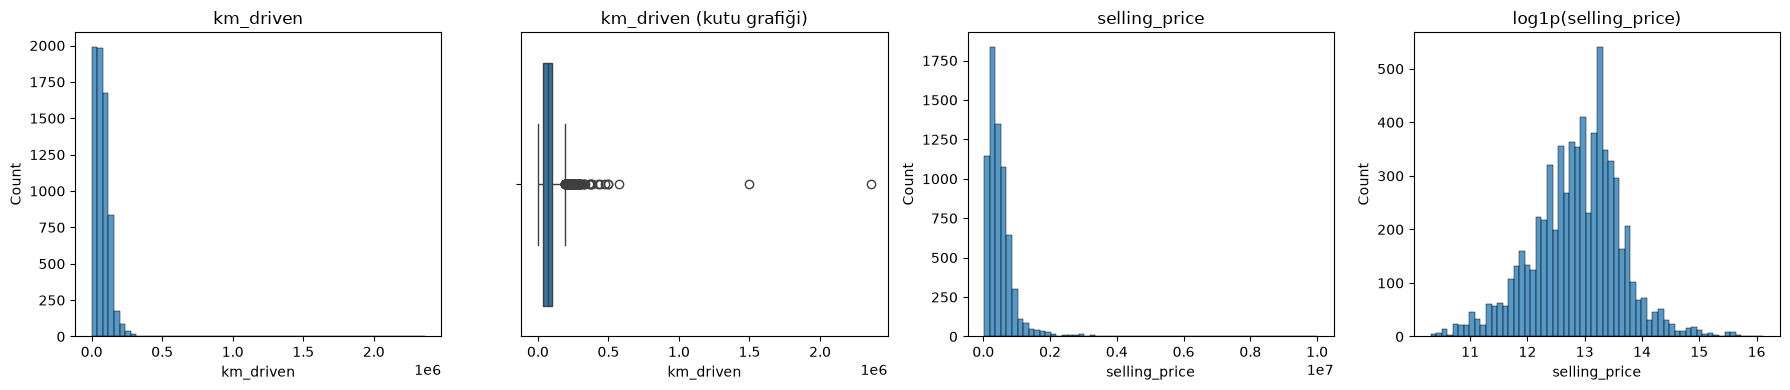

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(df["km_driven"], bins=60, ax=axes[0]).set(title="km_driven")
sns.boxplot(x=df["km_driven"], ax=axes[1]).set(title="km_driven (kutu grafiği)")
sns.histplot(df["selling_price"], bins=60, ax=axes[2]).set(title="selling_price")
sns.histplot(np.log1p(df["selling_price"]), bins=60, ax=axes[3]).set(title="log1p(selling_price)")
fig.tight_layout(); fig.savefig(FIG_DIR / "dagilimlar.png", dpi=150)
print("Çarpıklık (skew): km_driven =", round(df["km_driven"].skew(), 2),
      "| selling_price =", round(df["selling_price"].skew(), 2),
      "| log1p(selling_price) =", round(np.log1p(df["selling_price"]).skew(), 2))

In [12]:
# Aykırı değerler: IQR yöntemi (Q1 - 1.5·IQR, Q3 + 1.5·IQR). Yalnız raporlanır, hiçbir satır silinmez.
# seats ve owner kesikli kodlar olduğu için dahil edilmedi.
outlier_cols = ["year", "km_driven", "mileage", "engine", "max_power", REG_TARGET]
bounds = ["Q1", "Q3", "alt_sınır", "üst_sınır"]
save_table(iqr_outliers(df, outlier_cols).round({c: 2 for c in bounds}), "aykiri_degerler_iqr")

,sütun,Q1,Q3,alt_sınır,üst_sınır,aykırı_sayısı,aykırı_oranı
0,year,2011.0,2017.00,2002.00,2026.0,74,0.0109
1,km_driven,39395.0,100000.00,-51512.50,190907.5,164,0.0241
2,mileage,16.8,22.32,8.52,30.6,1,0.0002
3,engine,1197.0,1498.00,745.50,1949.5,1203,0.1819
4,max_power,68.0,100.00,20.00,148.0,305,0.0461
5,selling_price,250000.0,640000.00,-335000.00,1225000.0,323,0.0474


In [13]:
cls = df[CLF_TARGET].value_counts().to_frame("adet").assign(oran=lambda d: (d["adet"] / len(df)).round(4))
save_table(cls.reset_index(), "transmission_sinif_orani")

,transmission,adet,oran
0,Manual,6229,0.9143
1,Automatic,584,0.0857


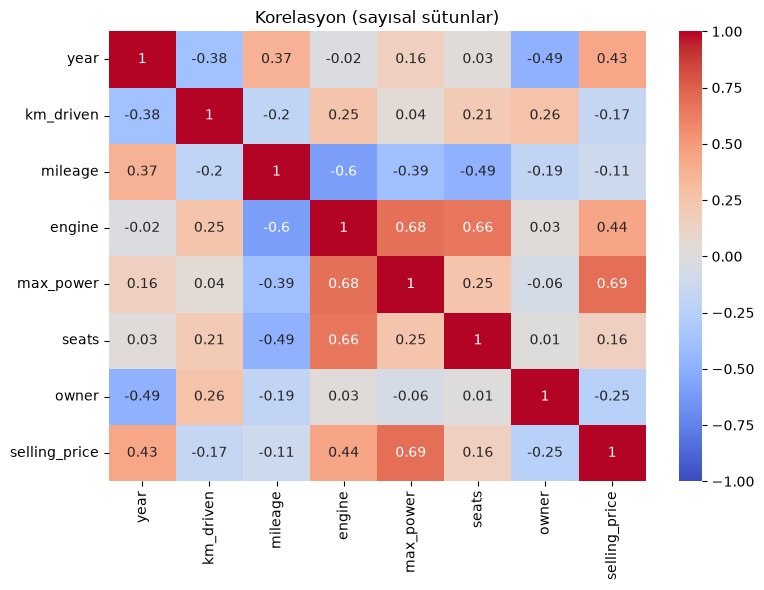

In [14]:
corr = df[NUM_FEATURES + [REG_TARGET]].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax).set(title="Korelasyon (sayısal sütunlar)")
fig.tight_layout(); fig.savefig(FIG_DIR / "korelasyon.png", dpi=150)

### Tek eğitim/test bölmesi

%80 eğitim / %20 test, `transmission`'a göre stratified, `random_state=SEED`. Üç görev de **aynı** bölmeyi kullanır.
Test kümesine yalnız son değerlendirmede dokunulur; model ve ayar seçimi eğitim kümesinde 5 katlı CV ile yapılır.

In [15]:
train, test = make_split(df)
print("Eğitim:", train.shape, "| Test:", test.shape)
print("Automatic oranı — eğitim:", round((train[CLF_TARGET] == "Automatic").mean(), 4),
      "| test:", round((test[CLF_TARGET] == "Automatic").mean(), 4))

Eğitim: (5450, 12) | Test: (1363, 12)
Automatic oranı — eğitim: 0.0857 | test: 0.0858


## 2. Sınıflandırma: `transmission` (Manual / Automatic)

- Gözlem: bir ilan (araç). X: 10 özellik (`selling_price` **yok**). y: 1 = Automatic, 0 = Manual.
- Modeller: Baseline (en sık sınıf), Random Forest, ANN (MLP). Ön işleme her modelle aynı `Pipeline` içinde.
- Model/ayar seçimi: eğitimde 5 katlı stratified CV, ölçüt macro-F1.

In [16]:
X_tr, y_tr = get_xy_clf(train)
X_te, y_te = get_xy_clf(test)
clf_searches = build_clf_searches()
clf_res = {name: evaluate_clf(s, X_tr, y_tr, X_te, y_te) for name, s in clf_searches.items()}
save_table(clf_results_table(clf_res), "siniflandirma_sonuclari")

,Model,CV,Eğitim,Test,Yorum
0,Baseline,0.478,0.478,0.478,
1,Random Forest,0.791,0.975,0.764,
2,ANN (MLP),0.728,0.656,0.669,


In [17]:
# Test kümesinde tüm metrikler (precision, recall, F1: macro ortalama)
detail = pd.DataFrame({
    name: {"accuracy": r["test_accuracy"], "precision": r["test_precision"],
           "recall": r["test_recall"], "f1": r["test_f1"]}
    for name, r in clf_res.items()
}).T.round(3)
save_table(detail.reset_index(names="Model"), "siniflandirma_test_metrikleri")

,Model,accuracy,precision,recall,f1
0,Baseline,0.914,0.457,0.500,0.478
1,Random Forest,0.924,0.757,0.772,0.764
2,ANN (MLP),0.933,0.948,0.615,0.669


In [18]:
for name in ["Random Forest", "ANN (MLP)"]:
    print(name, "en iyi ayar (CV):", clf_searches[name].best_params_)

Random Forest en iyi ayar (CV): {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 1}
ANN (MLP) en iyi ayar (CV): {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64,)}


In [19]:
# ANN mimari / alpha denemesi: CV katmanlarında ortalama eğitim ve doğrulama F1
save_table(mlp_experiment_table(clf_searches["ANN (MLP)"]), "mlp_deneyleri")

,Mimari,alpha,Eğitim F1,CV F1
0,"(16,)",0.0001,0.704,0.703
1,"(64,)",0.0001,0.731,0.728
2,"(64, 32)",0.0001,0.736,0.723
3,"(16,)",0.0100,0.704,0.703
4,"(64,)",0.0100,0.731,0.728
5,"(64, 32)",0.0100,0.735,0.723


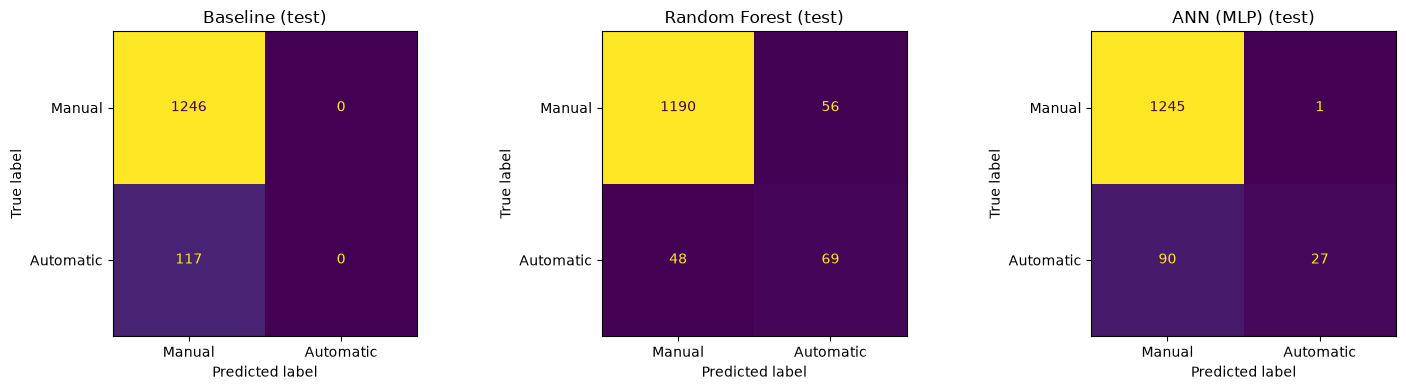

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, clf_res.items()):
    ConfusionMatrixDisplay(r["confusion_matrix"], display_labels=["Manual", "Automatic"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name} (test)")
fig.tight_layout(); fig.savefig(FIG_DIR / "karmasiklik_matrisleri.png", dpi=150)

In [21]:
# CV'ye göre en iyi model (baseline hariç) için test kümesi raporu
best_clf = max([k for k in clf_res if k != "Baseline"], key=lambda k: clf_res[k]["cv_f1"])
print("CV'ye göre seçilen model:", best_clf)
print(classification_report(y_te, clf_searches[best_clf].predict(X_te), target_names=["Manual", "Automatic"], digits=3))

CV'ye göre seçilen model: Random Forest
              precision    recall  f1-score   support

      Manual      0.961     0.955     0.958      1246
   Automatic      0.552     0.590     0.570       117

    accuracy                          0.924      1363
   macro avg      0.757     0.772     0.764      1363
weighted avg      0.926     0.924     0.925      1363



## 3. Regresyon: `selling_price` (INR)

- X: aynı 10 özellik (`transmission` **yok**). y: satış fiyatı.
- Modeller: Baseline (eğitim ortalaması), Ridge, Random Forest. Ridge ve RF `log1p(fiyat)` üzerinde öğrenir,
  tahmin `expm1` ile geri dönüştürülür; tüm metrikler orijinal fiyat ölçeğindedir.
- Model/ayar seçimi: eğitimde 5 katlı CV, ölçüt RMSE. Tablo hücreleri "eğitim / test".

In [22]:
Xr_tr, yr_tr = get_xy_reg(train)
Xr_te, yr_te = get_xy_reg(test)
reg_searches = build_reg_searches()
reg_res = {name: evaluate_reg(s, Xr_tr, yr_tr, Xr_te, yr_te) for name, s in reg_searches.items()}
save_table(reg_results_table(reg_res), "regresyon_sonuclari")

,Model,CV,MAE,MSE,RMSE,R²,MAPE,Yorum
0,Baseline,"517,501","291,376 / 297,678",2.684e+11 / 2.935e+11,"518,029 / 541,776",0.000 / -0.002,107.3% / 94.4%,
1,Ridge,"195,398","96,650 / 100,829",3.709e+10 / 4.436e+10,"192,582 / 210,608",0.862 / 0.849,20.6% / 20.0%,
2,Random Forest,"173,438","31,397 / 82,084",5.600e+09 / 3.120e+10,"74,833 / 176,645",0.979 / 0.893,6.7% / 16.3%,


In [23]:
for name in ["Ridge", "Random Forest"]:
    print(name, "en iyi ayar (CV):", reg_searches[name].best_params_)

Ridge en iyi ayar (CV): {'regressor__model__alpha': 0.1}
Random Forest en iyi ayar (CV): {'regressor__model__max_depth': 20, 'regressor__model__min_samples_leaf': 1}


CV'ye göre seçilen model: Random Forest


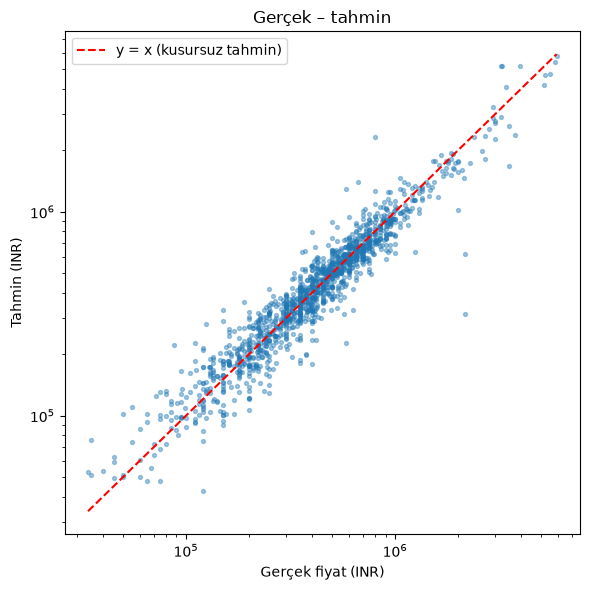

In [24]:
best_reg = min([k for k in reg_res if k != "Baseline"], key=lambda k: reg_res[k]["cv_rmse"])
print("CV'ye göre seçilen model:", best_reg)
plot_actual_vs_pred(yr_te, reg_searches[best_reg].predict(Xr_te), FIG_DIR / "gercek_tahmin.png")

## 4. Kümeleme

- Hedefler (`transmission`, `selling_price`) kümelemeye **girmez**. Özellikler: `CLUSTER_FEATURES`.
- Ön işleme: `km_driven` için `log1p`, medyan imputer, `StandardScaler`; yalnız eğitim kümesine fit edilir.
- KMeans, k = 2…10 için dirsek (inertia) ve silhouette.

Kümeleme özellikleri: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']


,k,inertia,silhouette
0,2,21883.28,0.4277
1,3,17125.98,0.2693
2,4,14933.30,0.2483
3,5,13037.24,0.2471
4,6,11902.67,0.2220
5,7,11067.48,0.2583
6,8,10165.52,0.2408
7,9,9520.56,0.2415
8,10,8991.89,0.2363


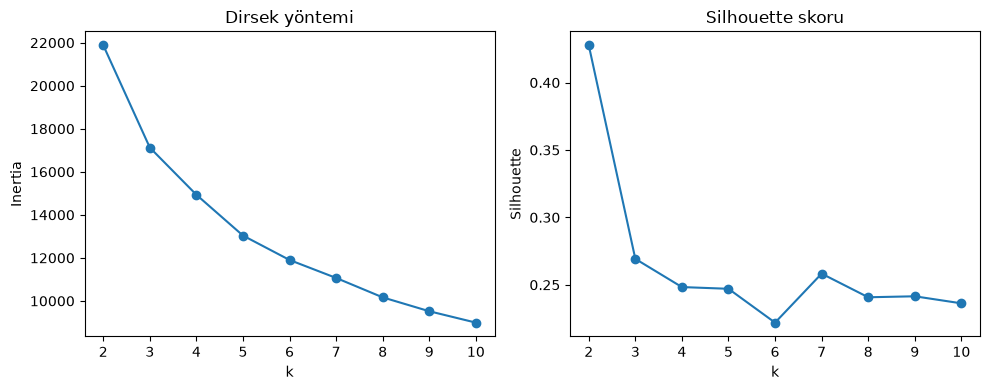

In [25]:
print("Kümeleme özellikleri:", CLUSTER_FEATURES)
X_cl = train[CLUSTER_FEATURES]
k_tbl = k_search(X_cl)
plot_k_search(k_tbl, FIG_DIR / "k_secimi.png")
save_table(k_tbl.round({"inertia": 2, "silhouette": 4}), "k_secimi")

Seçilen k = 2


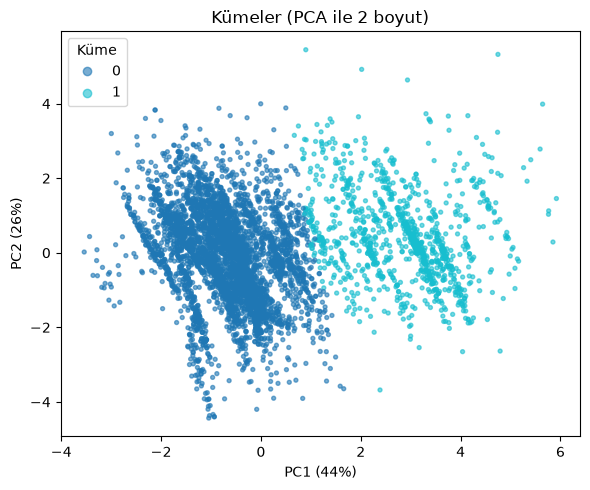

In [26]:
# Varsayılan: silhouette'i en yüksek k. Farklı bir k seçilecekse yalnız bu satır değiştirilir.
K = int(k_tbl.loc[k_tbl["silhouette"].idxmax(), "k"])
print("Seçilen k =", K)
km = fit_kmeans(X_cl, K)
labels = km.predict(X_cl)
plot_pca_clusters(km.named_steps["pre"].transform(X_cl), labels, FIG_DIR / "kumeler_pca.png")

In [27]:
# Küme profili. Fiyat ve vites türü kümelemeye girmedi; yalnız kümeleri sonradan yorumlamak için gösterilir.
save_table(profile_clusters(train, labels).round(3), "kume_profili")

,cluster,n,year,km_driven,mileage,engine,max_power,seats,median_selling_price,automatic_ratio,top_fuel,top_brand
0,0,4392,2014.0,60000.0,20.45,1248.0,76.9,5.0,360000.0,0.055,Petrol,Maruti
1,1,1058,2014.0,86750.0,14.24,2179.0,120.0,7.0,650000.0,0.213,Diesel,Mahindra


## 5. Veri sızıntısı ve deney tasarımı — yapılan kontroller

1. Birebir tekrar eden satırlar **bölmeden önce** silindi; `name`/`torque` atılınca oluşan tekrarlar da silindi.
2. Tek bölme: `test_size=0.2`, `stratify=transmission`, `random_state=42`; üç görev aynı indeksleri kullanır.
3. Imputer, scaler ve one-hot encoder `Pipeline` içinde: CV'de her katmanda yalnız o katmanın eğitim kısmına fit edilir.
4. Test kümesi yalnız son değerlendirmede kullanıldı; ayar seçimi eğitimde 5 katlı CV ile yapıldı.
5. Bir görevin hedefi diğer görevlerde özellik değil (aşağıdaki hücrede kontrol ediliyor).
6. `SEED = 42`: bölme, CV karıştırması, modeller ve KMeans.
7. Aynı kontroller `tests/` altında otomatik testlerle de doğrulanıyor (`pytest -q`).

In [28]:
assert set(train.index).isdisjoint(test.index)
assert REG_TARGET not in X_tr.columns and CLF_TARGET not in X_tr.columns
assert CLF_TARGET not in Xr_tr.columns and REG_TARGET not in Xr_tr.columns
assert CLF_TARGET not in CLUSTER_FEATURES and REG_TARGET not in CLUSTER_FEATURES
assert train.duplicated().sum() == 0 and not train.merge(test, how="inner").shape[0]
scaler = clf_searches["Random Forest"].best_estimator_.named_steps["pre"].named_transformers_["num"].named_steps["scale"]
assert np.allclose(scaler.mean_[0], train["year"].mean())  # scaler eğitimden öğrenildi
print("Tüm sızıntı kontrolleri geçti.")

Tüm sızıntı kontrolleri geçti.
